In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Read dataset and
shape inspection

In [13]:
df= pd.read_csv("/content/Unemployment in India.csv")
df.shape


(768, 7)

null value check

In [15]:
df.isnull().sum()


,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


type conversion


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [23]:
df.columns = df.columns.str.strip()
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

In [24]:
print(df.columns)

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')


In [27]:
df = df.rename(columns={
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Labour Participation Rate (%)": "Labour_Participation_Rate",
    "Estimated Employed": "Employed"
})
df.head()

,Region,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


EDA — Region-wise Average Unemployment

In [30]:
df = df.dropna()
df.isnull().sum()


,0
Region,0
Date,0
Frequency,0
Unemployment_Rate,0
Employed,0
Labour_Participation_Rate,0
Area,0


In [31]:
region_avg = df.groupby("Region")["Unemployment_Rate"].mean()

region_avg

,Unemployment_Rate
Region,
Andhra Pradesh,7.477143
Assam,6.428077
Bihar,18.918214
Chandigarh,15.991667
Chhattisgarh,9.240357
Delhi,16.495357
Goa,9.274167
Gujarat,6.663929
Haryana,26.283214


In [32]:
region_avg = (
    df.groupby("Region")["Unemployment_Rate"]
      .mean()
      .sort_values(ascending=False)
)

region_avg

,Unemployment_Rate
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


In [33]:
monthly_avg = (
    df.groupby("Date")["Unemployment_Rate"]
      .mean()
)

monthly_avg

,Unemployment_Rate
Date,
2019-05-31,8.874259
2019-06-30,9.303333
2019-07-31,9.033889
2019-08-31,9.637925
2019-09-30,9.051731
2019-10-31,9.900909
2019-11-30,9.868364
2019-12-31,9.497358
2020-01-31,9.950755


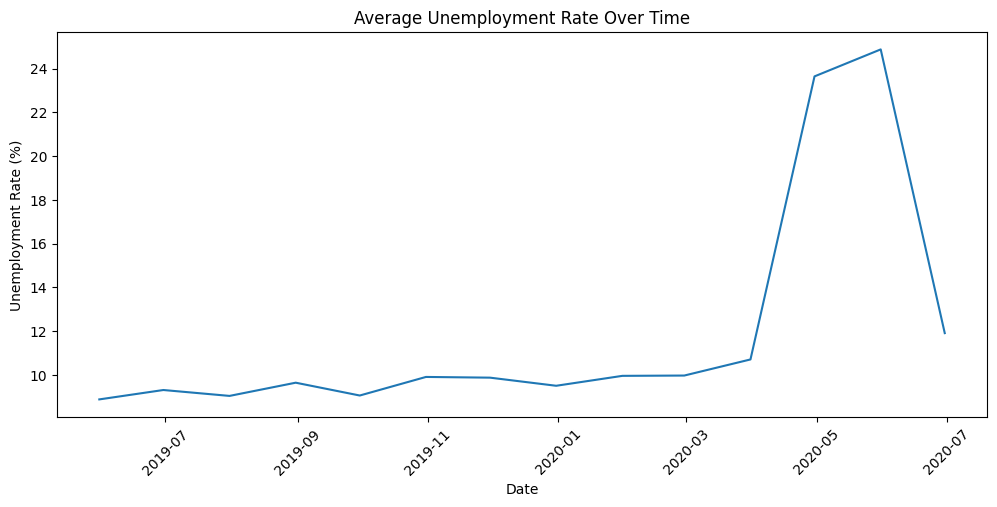

In [36]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_avg.index, monthly_avg.values)

plt.title("Average Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.show()

Stable Period (Mid-2019 to Early 2020): The unemployment rate remained low and relatively stable, hovering between approximately 9% and 10%.   Sharp Surge (From March 2020 Onward): The rate experienced a massive and rapid spike, jumping sharply from around 10% to peak at over 24% in mid-2020 (around May/summer), before showing a slight decrease thereafter.

In [39]:
df["Region"].unique()

array(['Andhra Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Goa',
       'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir',
       'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh',
       'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab',
       'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura',
       'Uttar Pradesh', 'Uttarakhand', 'West Bengal', 'Chandigarh'],
      dtype=object)

unemployment rate over time for at least 3 major states/regions



In [44]:
selected_regions = ["Delhi", "Maharashtra", "Kerala"]

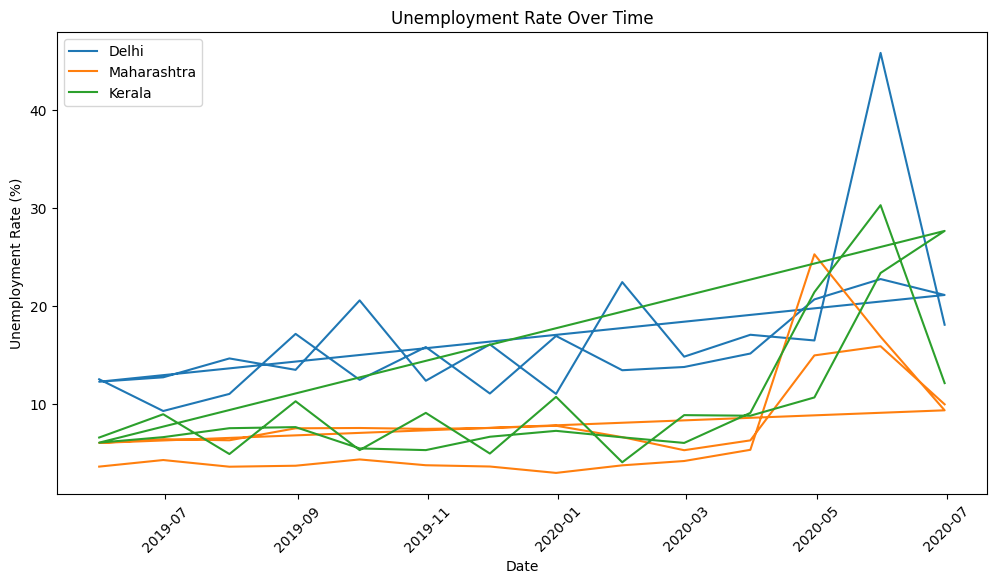

In [45]:
plt.figure(figsize=(12, 6))

for region in selected_regions:
    region_data = df[df["Region"] == region]

    plt.plot(
        region_data["Date"],
        region_data["Unemployment_Rate"],
        label=region
    )

plt.title("Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.legend()
plt.xticks(rotation=45)

plt.show()

Delhi (Blue Line): Consistently recorded higher unemployment rates compared to the other two regions throughout most of the period, generally ranging between 10% and 20%, followed by a massive and sharp spike reaching a peak of over 45% in mid-2020.   Kerala (Green Line): Started with moderate unemployment rates mostly between 5% and 15%, then saw a significant increase in mid-2020, peaking at around 30% before fluctuating downwards.   Maharashtra (Orange Line): Maintained the lowest unemployment rates for a long time (mostly under 10%), but also experienced a noticeable rise in mid-2020, reaching between 15% and 25%.   

Top 10 States with Highest Average Unemployment

In [46]:
top_10 = (
    df.groupby("Region")["Unemployment_Rate"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

top_10

,Unemployment_Rate
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


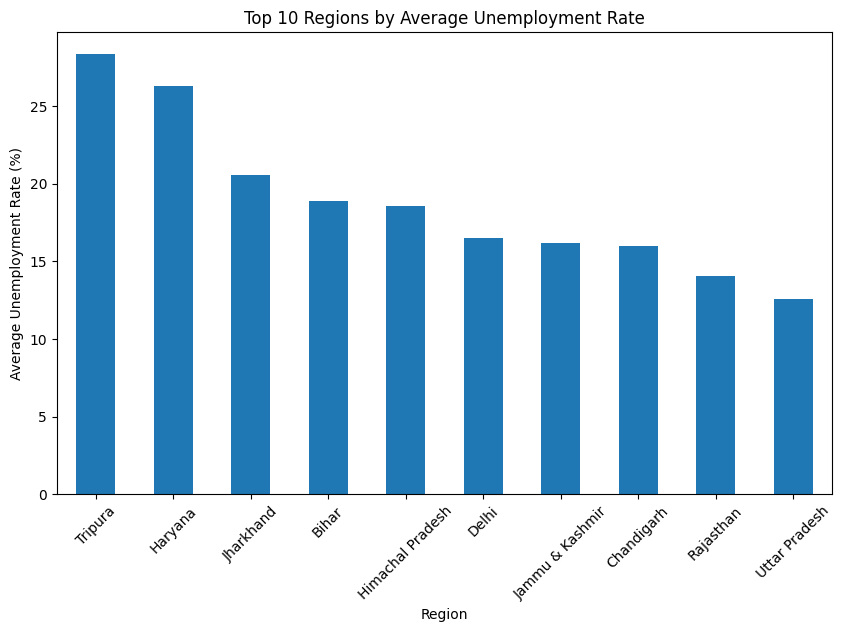

In [47]:
plt.figure(figsize=(10, 6))

top_10.plot(kind="bar")

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.show()

Correlation Heatmap

In [48]:
corr_data = df[
    [
        "Unemployment_Rate",
        "Employed",
        "Labour_Participation_Rate"
    ]
]

In [49]:
correlation = corr_data.corr()

correlation

,Unemployment_Rate,Employed,Labour_Participation_Rate
Unemployment_Rate,1.000000,-0.222876,0.002558
Employed,-0.222876,1.000000,0.011300
Labour_Participation_Rate,0.002558,0.011300,1.000000


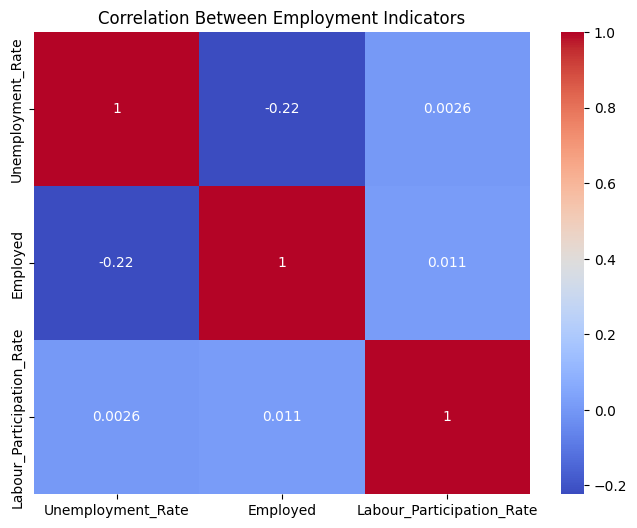

In [50]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Between Employment Indicators")

plt.show()

Pre-COVID vs Post-COVID

In [51]:
covid_date = pd.Timestamp("2020-03-01")

In [52]:
pre_covid = df[df["Date"] < covid_date]

post_covid = df[df["Date"] >= covid_date]

In [53]:
pre_covid_avg = pre_covid["Unemployment_Rate"].mean()
post_covid_avg = post_covid["Unemployment_Rate"].mean()

print("Pre-COVID Average:", pre_covid_avg)
print("Post-COVID Average:", post_covid_avg)

Pre-COVID Average: 9.509533582089553
Post-COVID Average: 17.774362745098042


In [54]:
print(
    "Pre-COVID Labour Participation:",
    pre_covid["Labour_Participation_Rate"].mean()
)

print(
    "Post-COVID Labour Participation:",
    post_covid["Labour_Participation_Rate"].mean()
)

Pre-COVID Labour Participation: 43.886119402985074
Post-COVID Labour Participation: 39.33004901960784


Comparison Chart

In [55]:
comparison = pd.DataFrame({
    "Period": ["Pre-COVID", "Post-COVID"],
    "Unemployment Rate": [
        pre_covid_avg,
        post_covid_avg
    ]
})

comparison

,Period,Unemployment Rate
0,Pre-COVID,9.509534
1,Post-COVID,17.774363


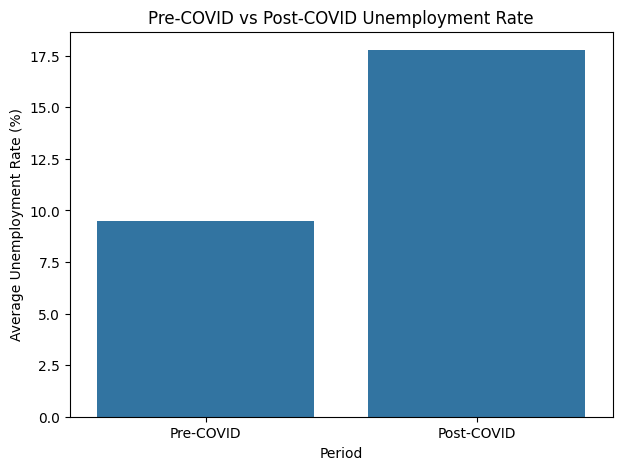

In [56]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=comparison,
    x="Period",
    y="Unemployment Rate"
)

plt.title("Pre-COVID vs Post-COVID Unemployment Rate")
plt.ylabel("Average Unemployment Rate (%)")

plt.show()

Conclusion

The analysis shows clear variation in unemployment rates across regions and over time. The time-series analysis highlights changes in unemployment around the COVID-19 period. The comparison between pre-COVID and post-COVID periods helps demonstrate the effect of the pandemic on unemployment. The correlation analysis also provides insights into the relationship between unemployment, employment, and labour force participation.